# Mushroom Classification Using Machine Learning

**Goal:** Predict whether a mushroom is **edible** or **poisonous** from its physical characteristics, and compare two classifiers: **Decision Tree** and **K-Nearest Neighbors (KNN)**.

## 1. Problem Statement and Introduction

**What the model predicts:** For each mushroom, the model predicts one of two classes: *edible* or *poisonous*.

**Why it is useful:** Eating a wrong wild mushroom can cause serious illness or death. A model that learns patterns from many labelled examples shows how data can support safety decisions, and it is a classic beginner example of binary classification.

**Target variable:** `class` (`e` = edible, `p` = poisonous).

**Input features:** 22 categorical (text) columns that describe the mushroom, such as `cap-shape`, `cap-color`, `odor`, `gill-size`, `stalk-root`, `spore-print-color`, `population` and `habitat`.

**Limitations for real-world safety decisions:**
- The dataset is small and old (8,124 records from a field guide), so it does not cover all mushroom species in the world.
- No model is perfect. Even one wrong "edible" prediction for a poisonous mushroom can be dangerous.
- Real mushrooms vary with region, season and age, which this dataset does not capture.
- **This project is for learning only. Never use it to decide whether to eat a mushroom.**

## 2. Data Preparation
### 2.1 Import libraries

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

sns.set_style("whitegrid")

### 2.2 Load the dataset
The notebook uses `mushrooms.csv` from the same folder. If the file is missing, it downloads it from a public GitHub mirror of the UCI Mushroom dataset (see the README for details).

In [ ]:
DATA_FILE = "mushrooms.csv"
MIRROR_URL = "https://raw.githubusercontent.com/kcncell/Mushroom-dataset/master/mushrooms.csv"

if os.path.exists(DATA_FILE):
    df = pd.read_csv(DATA_FILE)
else:
    df = pd.read_csv(MIRROR_URL)   # download from the public mirror
    df.to_csv(DATA_FILE, index=False)

print("Dataset loaded successfully.")

Dataset loaded successfully.


### 2.3 First look at the data

In [ ]:
print("First five rows:")
display(df.head())

print("\nShape (rows, columns):", df.shape)
print("\nColumn names:")
print(list(df.columns))
print("\nData types:")
print(df.dtypes)

First five rows:


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g



Shape (rows, columns): (8124, 23)

Column names:
['class', 'cap-shape', 'cap-surface', 'cap-color', 'bruises', 'odor', 'gill-attachment', 'gill-spacing', 'gill-size', 'gill-color', 'stalk-shape', 'stalk-root', 'stalk-surface-above-ring', 'stalk-surface-below-ring', 'stalk-color-above-ring', 'stalk-color-below-ring', 'veil-type', 'veil-color', 'ring-number', 'ring-type', 'spore-print-color', 'population', 'habitat']

Data types:
class                       str
cap-shape                   str
cap-surface                 str
cap-color                   str
bruises                     str
odor                        str
gill-attachment             str
gill-spacing                str
gill-size                   str
gill-color                  str
stalk-shape                 str
stalk-root                  str
stalk-surface-above-ring    str
stalk-surface-below-ring    str
stalk-color-above-ring      str
stalk-color-below-ring      str
veil-type                   str
veil-color             

### 2.4 Missing values and duplicate rows
In this dataset, missing values are written as the symbol `?` instead of an empty cell, so `isnull()` alone will not find them. We first replace `?` with `NaN`, then count the missing values.

In [ ]:
df = df.replace("?", np.nan)

missing = df.isnull().sum()
print("Columns with missing values:")
print(missing[missing > 0])

print("\nNumber of duplicate rows:", df.duplicated().sum())

Columns with missing values:
stalk-root    2480
dtype: int64

Number of duplicate rows: 0


**How we handle missing values:** Only `stalk-root` has missing values. Dropping them would remove about 30% of the data, so we keep the rows and fill the gaps with a separate category called `"missing"`. This is done inside the pipeline (Section 3), so it is learned only from the training data and cannot leak information from the test set.

The duplicate check shows whether any rows repeat. Any duplicates are reported above; because mushrooms can genuinely share the same characteristics, we do not delete rows without a clear reason.

### 2.5 Class distribution

class
e    4208
p    3916
Name: count, dtype: int64


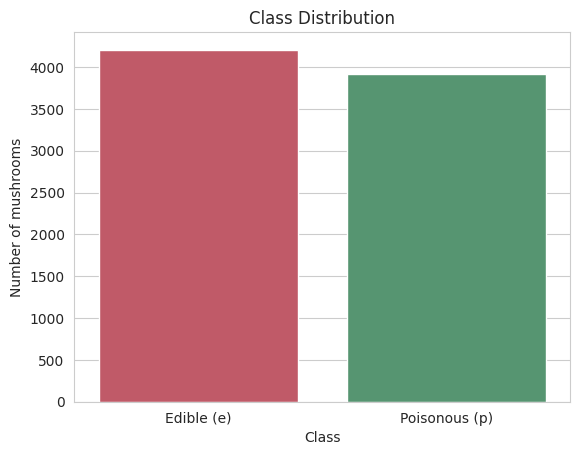

In [ ]:
print(df["class"].value_counts())

ax = sns.countplot(x="class", data=df, order=["e", "p"], hue="class", palette=["#4c9f70", "#d1495b"], legend=False)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Edible (e)", "Poisonous (p)"])
ax.set_title("Class Distribution")
ax.set_xlabel("Class")
ax.set_ylabel("Number of mushrooms")
plt.show()

The two classes are close in size, so the data is fairly balanced and accuracy is a reasonable metric. We still use a stratified split to keep the same class proportions in both sets.

### 2.6 Separate features (X) and target (y)
We convert the target to numbers: **0 = edible**, **1 = poisonous**.

In [ ]:
X = df.drop("class", axis=1)
y = df["class"].map({"e": 0, "p": 1})

class_names = ["Edible", "Poisonous"]   # index 0 -> Edible, index 1 -> Poisonous

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (8124, 22)
y shape: (8124,)


### 2.7 Train-test split
We use 80% of the data for training and 20% for testing. `stratify=y` keeps the edible/poisonous ratio the same in both sets, and `random_state=42` makes the results repeatable.

We split **before** any preprocessing so the test data stays completely unseen, which avoids data leakage.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

print("Training set:", X_train.shape)
print("Testing set :", X_test.shape)
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))
print("\nTesting class proportions:")
print(y_test.value_counts(normalize=True).round(3))

Training set: (6499, 22)
Testing set : (1625, 22)

Training class proportions:
class
0    0.518
1    0.482
Name: proportion, dtype: float64

Testing class proportions:
class
0    0.518
1    0.482
Name: proportion, dtype: float64


### 2.8 Preprocessing (encoding categorical features)
All features are categories (letters), and models need numbers. We use:
1. `SimpleImputer` to fill missing values with the category `"missing"`.
2. `OneHotEncoder` to turn each category into its own 0/1 column. `handle_unknown="ignore"` prevents errors if a category appears only in the test data.

These steps are placed inside a **Pipeline** together with the model. When we call `fit` on the training data, the imputer and encoder learn only from the training data, which prevents data leakage.

**Scaling note:** After one-hot encoding, every feature is already 0 or 1, so all features are on the same scale. Extra scaling is not needed for KNN here.

In [ ]:
categorical_cols = X.columns.tolist()

def make_preprocessor():
    categorical_steps = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer(transformers=[("cat", categorical_steps, categorical_cols)])

print("Number of input columns before encoding:", len(categorical_cols))

Number of input columns before encoding: 22


## 3. Model Building
We build two pipelines. Each one runs preprocessing first and then the classifier.

### 3.1 Decision Tree
A Decision Tree asks a series of yes/no questions about the features (for example, "is the odor foul?") and follows the answers to a final prediction.

In [ ]:
tree_model = Pipeline(steps=[
    ("preprocess", make_preprocessor()),
    ("classifier", DecisionTreeClassifier(random_state=42)),
])

tree_model.fit(X_train, y_train)
print("Decision Tree trained.")

Decision Tree trained.


### 3.2 K-Nearest Neighbors (KNN)
KNN predicts a mushroom's class by looking at the `k` most similar mushrooms in the training data and choosing the most common class among them. We use `k = 5`.

In [ ]:
knn_model = Pipeline(steps=[
    ("preprocess", make_preprocessor()),
    ("classifier", KNeighborsClassifier(n_neighbors=5)),
])

knn_model.fit(X_train, y_train)
print("KNN trained.")

KNN trained.


## 4. Model Evaluation
Both models predict on the **same test set**. We use:
- **Accuracy:** the share of correct predictions.
- **Confusion matrix:** shows correct and wrong predictions for each class.
- **Classification report:** precision, recall and F1-score per class.

In the confusion matrix, rows are the **actual** class and columns are the **predicted** class. The most dangerous mistake is predicting *Edible* for a mushroom that is actually *Poisonous*.

Decision Tree
Accuracy: 1.0000



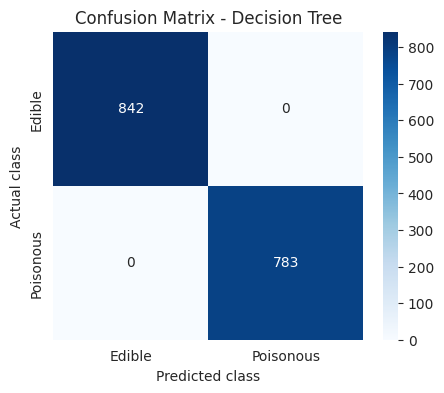

Classification Report:
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625

Poisonous mushrooms wrongly predicted as Edible: 0



In [ ]:
def evaluate_model(name, model):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)

    print("=" * 55)
    print(name)
    print("=" * 55)
    print(f"Accuracy: {acc:.4f}\n")

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted class")
    plt.ylabel("Actual class")
    plt.show()

    print("Classification Report:")
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))

    # Dangerous mistakes: actual Poisonous (1) but predicted Edible (0)
    dangerous = cm[1, 0]
    print(f"Poisonous mushrooms wrongly predicted as Edible: {dangerous}\n")
    return acc, dangerous

tree_acc, tree_danger = evaluate_model("Decision Tree", tree_model)

K-Nearest Neighbors (KNN)
Accuracy: 1.0000



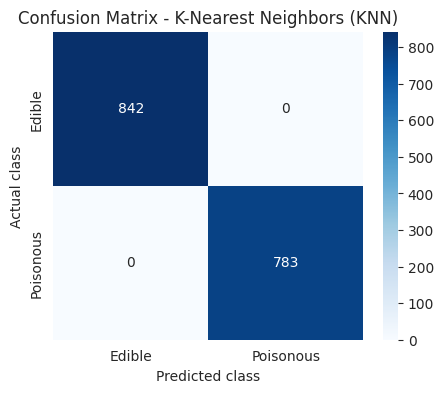

Classification Report:
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625

Poisonous mushrooms wrongly predicted as Edible: 0



In [ ]:
knn_acc, knn_danger = evaluate_model("K-Nearest Neighbors (KNN)", knn_model)

### 4.1 Results comparison table

,Model,Test Accuracy,Poisonous Predicted as Edible
0,Decision Tree,1.0,0
1,KNN (k=5),1.0,0


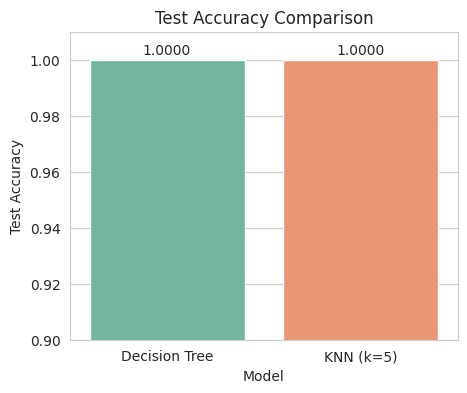

In [ ]:
results = pd.DataFrame({
    "Model": ["Decision Tree", "KNN (k=5)"],
    "Test Accuracy": [tree_acc, knn_acc],
    "Poisonous Predicted as Edible": [tree_danger, knn_danger],
})
results["Test Accuracy"] = results["Test Accuracy"].round(4)
display(results)

plt.figure(figsize=(5, 4))
ax = sns.barplot(x="Model", y="Test Accuracy", data=results, hue="Model", palette="Set2", legend=False)
ax.set_ylim(0.9, 1.01)
ax.set_title("Test Accuracy Comparison")
for i, v in enumerate(results["Test Accuracy"]):
    ax.text(i, v + 0.002, f"{v:.4f}", ha="center")
plt.show()

### 4.2 Which model performed better?
The code below decides based on the actual test results (accuracy first, then fewer dangerous mistakes).

In [ ]:
if tree_acc > knn_acc:
    verdict = "Decision Tree performed better (higher test accuracy)."
elif knn_acc > tree_acc:
    verdict = "KNN performed better (higher test accuracy)."
else:
    if tree_danger < knn_danger:
        verdict = "Both models have the same accuracy; Decision Tree made fewer dangerous mistakes."
    elif knn_danger < tree_danger:
        verdict = "Both models have the same accuracy; KNN made fewer dangerous mistakes."
    else:
        verdict = "Both models performed equally on this test set."

print(f"Decision Tree accuracy: {tree_acc:.4f}")
print(f"KNN accuracy          : {knn_acc:.4f}")
print("Result:", verdict)

Decision Tree accuracy: 1.0000
KNN accuracy          : 1.0000
Result: Both models performed equally on this test set.


## 5. Conclusion

In [ ]:
print("CONCLUSION (generated from this run's results)")
print("-" * 50)
print(f"Better model : {verdict}")
print(f"Accuracy     : Decision Tree = {tree_acc:.4f}, KNN = {knn_acc:.4f}")
print(f"Dangerous errors (poisonous predicted edible): Decision Tree = {tree_danger}, KNN = {knn_danger}")

CONCLUSION (generated from this run's results)
--------------------------------------------------
Better model : Both models performed equally on this test set.
Accuracy     : Decision Tree = 1.0000, KNN = 1.0000
Dangerous errors (poisonous predicted edible): Decision Tree = 0, KNN = 0


### What I learned
- **Data preparation:** Real datasets can hide missing values behind symbols like `?`. Categorical text must be encoded as numbers, and the train-test split must be done *before* preprocessing so that the test set stays unseen.
- **Classification:** A Decision Tree learns rules from features, while KNN compares a new mushroom with similar known ones. Both can work well when the features are very informative, as they are in this dataset.
- **Model evaluation:** Accuracy alone is not enough. Precision, recall and F1-score show how each class is handled.
- **Confusion matrices:** They show exactly which mistakes a model makes. Here, predicting "Edible" for a poisonous mushroom is far more serious than the opposite mistake.

### Limitations of this project
- The dataset is small, old and limited to certain mushroom families, so results may not transfer to mushrooms outside it.
- The features are expert descriptions, not photos, and in real life people may describe mushrooms incorrectly.
- We used only one train-test split and default settings (no cross-validation or tuning), so the scores come from a single split.
- Very high accuracy on this dataset does not make the model safe for real use. **Never rely on this model to decide whether a mushroom is safe to eat.**